# DuckDB Masterclass — Capítulo 08
## Federação SQLite e caminhos para PostgreSQL/MySQL

**Edição didática para estudo autônomo e publicação**  
**Contexto:** Operations Analytics e telecomunicações | **Dados:** sintéticos  
**Roteiro:** hipótese → executar → validar → interpretar → desafio → autoavaliação.

> Execute as células **de cima para baixo** em um kernel limpo. Resultados reais só devem ser salvos depois da execução no seu ambiente. Não publique dados privados, credenciais ou caminhos absolutos.

## 08.1 — Objetivos e diagnóstico

- Criar uma fonte SQLite local usando `sqlite3`.
- Consultar a fonte pelo DuckDB quando a extensão estiver disponível.
- Executar alternativa offline caso a extensão não exista.
- Diferenciar consulta federada e materialização.

**Pergunta de partida:** que risco operacional aparece quando utilizamos essa tecnologia de forma inadequada?

## 08.2 — Conceitos essenciais

Federação permite ler fontes externas sem copiá-las integralmente para tabelas DuckDB. SQLite é uma demonstração local reproduzível; PostgreSQL e MySQL têm extensões e pré-requisitos próprios. O exercício local **não** demonstra conectividade a servidores corporativos.

### 🗺️ Modelo visual — Federação SQLite e caminhos para PostgreSQL/MySQL

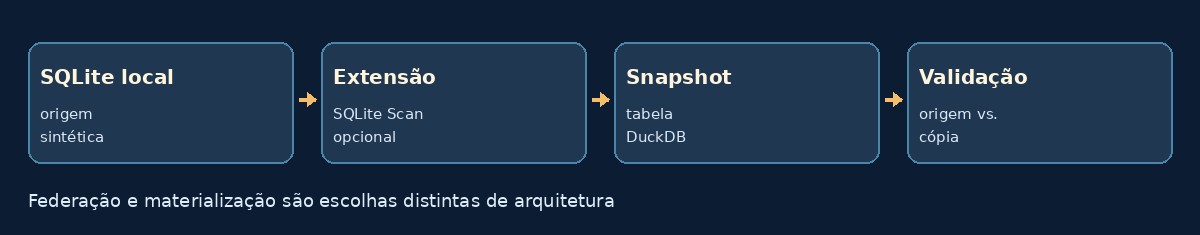

*Ilustração esquemática; não representa medição experimental.*

## 08.3 — Preparação e pré-requisitos

- Kernel recomendado: **Python (DuckDB Masterclass)**.
- Instale dependências ausentes no seu ambiente, fora do fluxo dos laboratórios.
- Cada arquivo produzido é sintético e deve ser salvo em pasta temporária ou `dados/` (ignorada pelo Git).
- Não execute instalação de extensões externas sem entender a necessidade, conectividade e eventuais custos.

## 08.4 — 🔬 Criar fonte SQLite sintética

**Hipótese / tarefa:** Gerar três ordens técnicas em banco temporário.

In [ ]:
import duckdb,sqlite3,tempfile
from pathlib import Path
from IPython.display import display
con=duckdb.connect(':memory:')
tmp_sqlite=tempfile.TemporaryDirectory()
arquivo_sqlite=Path(tmp_sqlite.name)/'fonte_operacional.sqlite'
with sqlite3.connect(str(arquivo_sqlite)) as fonte:
    fonte.execute('CREATE TABLE ordens(id INTEGER PRIMARY KEY,status TEXT)')
    fonte.executemany('INSERT INTO ordens VALUES (?,?)',[(1,'aberta'),(2,'fechada'),(3,'fechada')])
print('Fonte SQLite local criada; registros:',3)

**Interpretação e limite:** Dados criados localmente; sem senha ou rede.

## 08.5 — 🔬 Ler fonte SQLite pelo DuckDB ou fallback

**Hipótese / tarefa:** Tentar carregar extensão SQLite previamente instalada; usar `sqlite3` na ausência.

In [ ]:
# Dependência opcional: somente LOAD, sem instalação automática.
fonte_via_duckdb=False
try:
    con.execute('LOAD sqlite')
    consulta=f"SELECT * FROM sqlite_scan('{arquivo_sqlite.as_posix()}','ordens') ORDER BY id"
    fonte_via_duckdb=True
    leitura=con.execute(consulta).df()
except Exception as exc:
    print('Extensão SQLite não disponível; usando fallback Python:',type(exc).__name__)
    import pandas as pd
    with sqlite3.connect(str(arquivo_sqlite)) as fonte:
        leitura=pd.read_sql_query('SELECT * FROM ordens ORDER BY id',fonte)
display(leitura)
assert len(leitura)==3

**Interpretação e limite:** Fallback não é federação via DuckDB; as duas rotas devem ser diferenciadas.

## 08.6 — 🔬 Materializar dados no DuckDB

**Hipótese / tarefa:** Comparar resultado da leitura externa com cópia local.

In [ ]:
con.register('leitura_sqlite',leitura)
con.execute('CREATE TABLE ordens_snapshot AS SELECT * FROM leitura_sqlite')
res=con.execute('SELECT status,COUNT(*) n FROM ordens_snapshot GROUP BY status ORDER BY status').df()
display(res)
assert int(res['n'].sum())==3

**Interpretação e limite:** Materializar produz snapshot; alterações posteriores na origem podem não aparecer.

## 08.7 — 🔬 Simular atualização na origem

**Hipótese / tarefa:** Mudar um status em SQLite e observar diferença entre fonte e snapshot.

In [ ]:
with sqlite3.connect(str(arquivo_sqlite)) as fonte:
    fonte.execute("UPDATE ordens SET status='reaberta' WHERE id=1")
    status_fonte=fonte.execute('SELECT status FROM ordens WHERE id=1').fetchone()[0]
status_snapshot=con.execute('SELECT status FROM ordens_snapshot WHERE id=1').fetchone()[0]
print('Origem:',status_fonte,'| snapshot:',status_snapshot)
assert status_fonte=='reaberta' and status_snapshot=='aberta'

**Interpretação e limite:** Requer definir política de atualização dos dados.

## 08.8 — 🎯 Desafio profissional

Em um pipeline de chamados, quais riscos surgem ao consultar tabelas externas diretamente? Compare latência, atualização e acesso.

**Critério de aceite:** apresentar a consulta ou procedimento, verificar uma hipótese e explicar pelo menos uma limitação. Resolva antes de consultar a referência abaixo.

### 🧠 Solução comentada / critérios de conferência

Não trate a cópia materializada como espelho atualizado automaticamente; documente atualização, autenticação e consistência.

## 08.9 — Autoavaliação

1. Explique o recurso sem reproduzir o código.
2. O que foi efetivamente demonstrado?
3. Que caso-limite poderia invalidar a interpretação?
4. Como validar a resposta com `assert`, SQL ou inspeção do plano?
5. Quando aplicaria isso em operações de telecomunicações?

**Gabarito orientador:** consulte a solução comentada do desafio e compare sua resposta com os resultados efetivamente observados; não conclua propriedades de performance ou produção sem evidência.

## 08.10 — Referências, reprodução e publicação

- [SQLite Extension](https://duckdb.org/docs/stable/core_extensions/sqlite)
- [PostgreSQL Extension](https://duckdb.org/docs/stable/core_extensions/postgres)
- [MySQL Extension](https://duckdb.org/docs/stable/core_extensions/mysql)

**Notas de engenharia:** O laboratório não solicita credenciais nem acessa serviços corporativos; carga SQLite opcional pode exigir extensão local instalada.

**Checklist editorial:** executar `Restart & Run All` quando aplicável; salvar saídas úteis; revisar integridade, privacidade, dependências e gráficos antes do `git add`.